<a href="https://colab.research.google.com/github/Maxowino/SemProject_MLEngine/blob/main/V2%20dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

147119 152253 SEM Project

In [1]:


import pandas as pd

# Load
df = pd.read_csv("/content/Software Questions.csv", encoding="latin1")



In [ ]:
# a no of rows
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 200
Number of columns: 5


In [ ]:
# b datatypes
df.dtypes

,0
Question Number,int64
Question,object
Answer,object
Category,object
Difficulty,object


In [ ]:
# c check for missing values
df.isnull().sum()

,0
Question Number,0
Question,0
Answer,0
Category,0
Difficulty,0


In [ ]:
# d spliting to form new dataset

# first 15 rows
first_15 = df.head(15)

#  last 20 rows
last_20 = df.tail(20)

# Merge
df_sample = pd.concat([first_15, last_20], ignore_index=True)

# Display the new dataset
df_sample

,Question Number,Question,Answer,Category,Difficulty
0,1,What is the difference between compilation and...,Compilation translates source code into machin...,General Programming,Medium
1,2,Explain the concept of polymorphism.,Polymorphism allows objects of different class...,General Programming,Medium
2,3,Define encapsulation and give an example.,Encapsulation bundles data and methods in a cl...,General Programming,Hard
3,4,"What is an abstract class, and how is it diffe...",An abstract class can't be instantiated and ca...,General Programming,Medium
4,5,Describe the principles of Object-Oriented Pro...,"OOP principles include encapsulation, inherita...",General Programming,Medium
5,6,What is the purpose of a constructor?,A constructor initializes object properties up...,General Programming,Medium
6,7,Explain the difference between stack and heap ...,Stack memory stores local variables and functi...,General Programming,Medium
7,8,"What is a design pattern, and can you name a few?",Design patterns are solutions to common design...,General Programming,Medium
8,9,"Define the term ""DRY"" in software development.",DRY (Don't Repeat Yourself) advocates for avoi...,General Programming,Medium
9,10,What is the SOLID principle?,SOLID represents five design principles for OO...,General Program,Hard


In [ ]:
# e. Check the categories
print("Categories:")
print(df_sample["Category"].value_counts())

# f. Check the difficulty
print("\nDifficulty levels:")
print(df_sample["Difficulty"].value_counts())

# g. Check category against difficulty
print("\nCategory vs Difficulty:")
print(pd.crosstab(df_sample["Category"], df_sample["Difficulty"]))

Categories:
Category
General Programming    9
System Design          6
Algorithms             5
Data Structures        5
Machine Learning       2
Distributed Systems    2
General Program        1
Networking             1
Low-level Systems      1
Database Systems       1
Data Engineering       1
Security               1
Name: count, dtype: int64

Difficulty levels:
Difficulty
Hard      23
Medium    11
Easy       1
Name: count, dtype: int64

Category vs Difficulty:
Difficulty           Easy  Hard  Medium
Category                               
Algorithms              0     5       0
Data Engineering        0     1       0
Data Structures         1     1       3
Database Systems        0     1       0
Distributed Systems     0     2       0
General Program         0     1       0
General Programming     0     1       8
Low-level Systems       0     1       0
Machine Learning        0     2       0
Networking              0     1       0
Security                0     1       0
System Desig

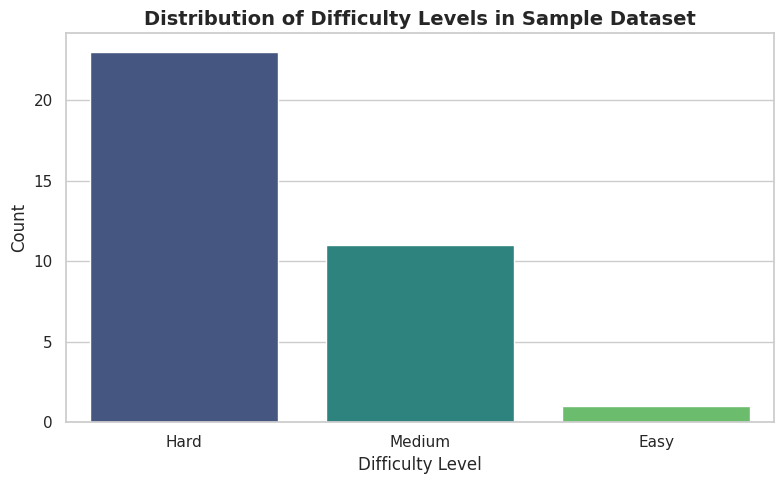

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Recreate df_sample in case the kernel was restarted
try:
    df_sample
except NameError:
    df = pd.read_csv("/content/Software Questions.csv", encoding="latin1")
    first_15 = df.head(15)
    last_20 = df.tail(20)
    df_sample = pd.concat([first_15, last_20], ignore_index=True)

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Create the bar chart for  distribution
plt.figure(figsize=(8, 5))
difficulty_counts = df_sample["Difficulty"].value_counts()

sns.barplot(
    x=difficulty_counts.index,
    y=difficulty_counts.values,
    hue=difficulty_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Distribution of Difficulty Levels in Sample Dataset", fontsize=14, fontweight='bold')
plt.xlabel("Difficulty Level", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.tight_layout()
plt.show()

In [2]:

# Step 2: Prepare the question bank

import pandas as pd

# Keep the columns needed by the app
question_bank = df[
    ["Question", "Answer", "Category", "Difficulty"]
].copy()

# Remove duplicate questions and rows with missing required data
question_bank = question_bank.dropna(
    subset=["Question", "Answer", "Category", "Difficulty"]
)

question_bank = question_bank.drop_duplicates(
    subset=["Question"]
)

# Remove unnecessary spaces
for column in ["Question", "Answer", "Category", "Difficulty"]:
    question_bank[column] = question_bank[column].astype(str).str.strip()

# Reset row numbering
question_bank = question_bank.reset_index(drop=True)

# Display the prepared question bank
print("Total questions:", len(question_bank))
print("\nQuestions by difficulty:")
print(question_bank["Difficulty"].value_counts())

print("\nQuestions by category:")
print(question_bank["Category"].value_counts())

question_bank.head()


Total questions: 174

Questions by difficulty:
Difficulty
Medium    92
Hard      76
Easy       6
Name: count, dtype: int64

Questions by category:
Category
System Design               24
DevOps                      15
Security                    13
Data Structures             11
Database and SQL            10
Languages and Frameworks    10
Software Testing            10
Algorithms                  10
Web Development             10
Version Control             10
General Programming          9
Front-end                    8
Back-end                     7
Distributed Systems          5
Machine Learning             5
Full-stack                   4
Low-level Systems            3
Networking                   3
Database Systems             3
Data Engineering             2
General Program              1
Artificial Intelligence      1
Name: count, dtype: int64


,Question,Answer,Category,Difficulty
0,What is the difference between compilation and...,Compilation translates source code into machin...,General Programming,Medium
1,Explain the concept of polymorphism.,Polymorphism allows objects of different class...,General Programming,Medium
2,Define encapsulation and give an example.,Encapsulation bundles data and methods in a cl...,General Programming,Hard
3,"What is an abstract class, and how is it diffe...",An abstract class can't be instantiated and ca...,General Programming,Medium
4,Describe the principles of Object-Oriented Pro...,"OOP principles include encapsulation, inherita...",General Programming,Medium


In [3]:
print("Number of Easy questions:",
      (df["Difficulty"].str.strip().str.lower() == "easy").sum())

Number of Easy questions: 7


In [4]:
print("Number of medium questions:",
      (df["Difficulty"].str.strip().str.lower() == "medium").sum())

Number of medium questions: 111


In [5]:
print("Number of hard questions:",
      (df["Difficulty"].str.strip().str.lower() == "hard").sum())

Number of hard questions: 82


In [6]:

# Create a separate copy for the question bank
question_bank = df.copy()

# Display the original distribution
print("Original distribution:")
print(question_bank["Difficulty"].value_counts())

# Calculate the percentages
print("\nOriginal percentages:")
print(
    (question_bank["Difficulty"].value_counts(normalize=True) * 100)
    .round(1)
)


Original distribution:
Difficulty
Medium    111
Hard       82
Easy        7
Name: count, dtype: int64

Original percentages:
Difficulty
Medium    55.5
Hard      41.0
Easy       3.5
Name: proportion, dtype: float64


In [7]:

# Step 3: Clean the question bank

import pandas as pd

# Keep the columns needed by the app
question_bank = df[
    ["Question", "Answer", "Category", "Difficulty"]
].copy()

# Remove rows missing essential information
question_bank = question_bank.dropna(
    subset=["Question", "Answer", "Category", "Difficulty"]
)

# Remove extra spaces
for col in ["Question", "Answer", "Category", "Difficulty"]:
    question_bank[col] = question_bank[col].astype(str).str.strip()

# Remove duplicate questions
question_bank = question_bank.drop_duplicates(
    subset=["Question"]
)

# Remove empty questions or answers
question_bank = question_bank[
    (question_bank["Question"] != "") &
    (question_bank["Answer"] != "")
]

# Reset row numbering
question_bank = question_bank.reset_index(drop=True)

# Check the results
print("Original rows:", len(df))
print("Cleaned questions:", len(question_bank))

print("\nDifficulty distribution:")
print(question_bank["Difficulty"].value_counts())

print("\nCategory distribution:")
print(question_bank["Category"].value_counts())

# Display sample questions
display(question_bank.head())


Original rows: 200
Cleaned questions: 174

Difficulty distribution:
Difficulty
Medium    92
Hard      76
Easy       6
Name: count, dtype: int64

Category distribution:
Category
System Design               24
DevOps                      15
Security                    13
Data Structures             11
Database and SQL            10
Languages and Frameworks    10
Software Testing            10
Algorithms                  10
Web Development             10
Version Control             10
General Programming          9
Front-end                    8
Back-end                     7
Distributed Systems          5
Machine Learning             5
Full-stack                   4
Low-level Systems            3
Networking                   3
Database Systems             3
Data Engineering             2
General Program              1
Artificial Intelligence      1
Name: count, dtype: int64


,Question,Answer,Category,Difficulty
0,What is the difference between compilation and...,Compilation translates source code into machin...,General Programming,Medium
1,Explain the concept of polymorphism.,Polymorphism allows objects of different class...,General Programming,Medium
2,Define encapsulation and give an example.,Encapsulation bundles data and methods in a cl...,General Programming,Hard
3,"What is an abstract class, and how is it diffe...",An abstract class can't be instantiated and ca...,General Programming,Medium
4,Describe the principles of Object-Oriented Pro...,"OOP principles include encapsulation, inherita...",General Programming,Medium
